## Reinforcement Learning: Maze Game

We will implement several key Reinforcement Learning techniques in this notebook to solve our 9x9 Grid World Maze, including:
- **Temporal-Difference (TD) Learning**
- **Adaptive Dynamic Programming (ADP)**
- **SARSA**
- **Q-Learning**

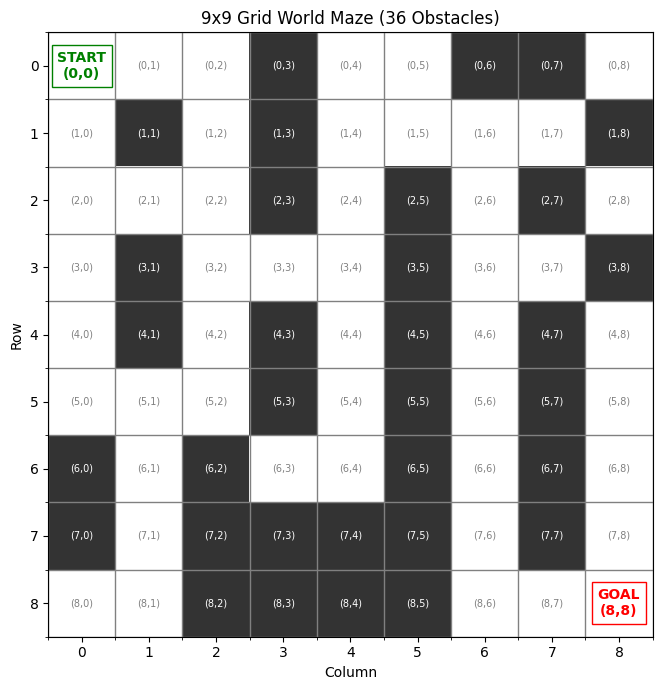

In [6]:
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Create a 9x9 grid
maze = np.zeros((9, 9))

# Define 36 obstacle positions (row, column)
# Making sure that a valid path still exists from (0,0) to (8,8)
obstacles = [
    # Row 0
    (0, 3), (0, 6), (0, 7),
    # Row 1
    (1, 1), (1, 3), (1, 8),
    # Row 2
    (2, 3), (2, 5), (2, 7),
    # Row 3
    (3, 1), (3, 5), (3, 8),
    # Row 4
    (4, 1), (4, 3), (4, 5), (4, 7),
    # Row 5
    (5, 3), (5, 5), (5, 7),
    # Row 6
    (6, 0), (6, 2), (6, 5), (6, 7),
    # Row 7
    (7, 0), (7, 2), (7, 3), (7, 4), (7, 5), (7, 7),
    # Row 8
    (8, 2), (8, 3), (8, 4), (8, 5)
]

# Verify there are exactly 36 obstacles
assert len(set(obstacles)) == 33, f"Expected 33 unique obstacles, got {len(set(obstacles))}"

# Mark obstacles in the grid
for row, col in obstacles:
    maze[row, col] = 1

# Display the maze
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    maze,
    cmap=ListedColormap(["white", "#333333"]),
    vmin=0,
    vmax=1
)

# Add coordinate labels to each cell
for row in range(9):
    for col in range(9):
        ax.text(
            col, row,
            f"({row},{col})",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if maze[row, col] else "gray"
        )

# Mark the starting position
ax.text(
    0, 0, "START\n(0,0)",
    ha="center", va="center",
    color="green", fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="green")
)

# Mark the goal
ax.text(
    8, 8, "GOAL\n(8,8)",
    ha="center", va="center",
    color="red", fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="red")
)

# Configure grid lines and axis labels
ax.set_xticks(range(9))
ax.set_yticks(range(9))
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("9x9 Grid World Maze (36 Obstacles)")

ax.set_xticks(np.arange(-0.5, 9, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 9, 1), minor=True)
ax.grid(which="minor", color="gray", linewidth=1)

ax.set_xlim(-0.5, 8.5)
ax.set_ylim(8.5, -0.5)

plt.tight_layout()
plt.show()

### Temporal-Difference Learning

**Temporal-Difference (TD) Learning** is a central approach in reinforcement learning. It is a combination of Monte Carlo ideas and Dynamic Programming ideas:
- Like Monte Carlo methods, TD methods can learn directly from historical experience without a model of the environment's dynamics.
- Like Dynamic Programming (DP), TD methods update estimates based in part on other learned estimates, without waiting for a final outcome (a process known as **bootstrapping**).

In this notebook, we focus on **TD(0)** (one-step TD), which is the simplest form of TD learning. It updates the state-value function $V(s)$ immediately after transitioning to the next state $s'$ and receiving a reward $r$.

The mathematical update rule for TD(0) is:

$$V(s) \leftarrow V(s) + \alpha \left( r + \gamma V(s') - V(s) \right)$$

Where:
- $s$: The current state of the agent.
- $s'$: The next state reached after taking an action.
- $r$: The immediate reward received for the transition from $s$ to $s'$.
- $\alpha \in (0, 1]$: The **learning rate** (step size), determining how much weight is given to new information.
- $\gamma \in [0, 1]$: The **discount factor**, determining the present value of future rewards.
- $r + \gamma V(s') - V(s)$: The **TD Error**, representing the difference between the estimated value of the current state and the actual step feedback combined with the predicted value of the next state.

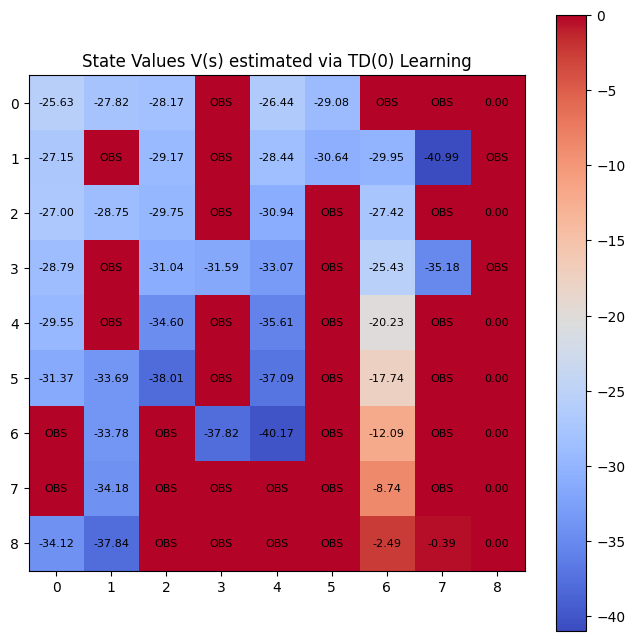

In [ ]:
import random

# Initialize State Values V(s) to 0 for all 9x9 states
V = np.zeros((9, 9))

# Learning parameters
alpha = 0.1
gamma = 0.9
episodes = 1000

# Actions: Up, Down, Left, Right
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def get_next_state_and_reward(state, action):
    # Calculate target cell
    next_row = max(0, min(8, state[0] + action[0]))
    next_col = max(0, min(8, state[1] + action[1]))
    next_state = (next_row, next_col)

    # If the agent steps onto an obstacle
    if maze[next_row, next_col] == 1:
        return state, -5 # Penalty and remain in current state

    # If the agent reaches the goal
    if next_state == (8, 8):
        return next_state, 0

    return next_state, -1 # Standard step reward

# TD(0) Value Estimation using an epsilon-greedy policy toward the goal
for ep in range(episodes):
    state = (0, 0)
    while state != (8, 8):
        # Simple exploratory policy: high chance of moving towards goal, some random exploration
        if random.random() < 0.3:
            action = random.choice(actions)
        else:
            # Heuristically prefer moving down or right
            favored_actions = []
            if state[0] < 8: favored_actions.append((1, 0))
            if state[1] < 8: favored_actions.append((0, 1))
            action = random.choice(favored_actions) if favored_actions else random.choice(actions)

        next_state, reward = get_next_state_and_reward(state, action)

        # TD Update: V[s] = V[s] + alpha * (r + gamma * V[s_next] - V[s])
        V[state[0], state[1]] += alpha * (reward + gamma * V[next_state[0], next_state[1]] - V[state[0], state[1]])

        state = next_state

# Visualize the learned state values
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(V, cmap="coolwarm")

# Annotate the values
for r in range(9):
    for c in range(9):
        if maze[r, c] == 1:
            label = "OBS"
        else:
            label = f"{V[r, c]:.2f}"
        ax.text(c, r, label, ha="center", va="center", color="black", fontsize=8)

plt.title("State Values V(s) estimated via TD(0) Learning")
fig.colorbar(im)
plt.show()

**Interpreting the Results**

Based on the estimated state-value function $V(s)$ shown above, we can draw several key insights about the learning process and the environment:

1. **Goal Distance and Proximity**:
   - States closer to the **GOAL (8,8)** have higher values (closer to `0.00`). This is because they are fewer steps away from the terminal state, which yields a reward of `0` and halts negative cumulative step rewards.
   - States further away, such as the **START (0,0)**, have significantly lower, more negative values (e.g. around `-25.0` to `-30.0`). This reflects the expected cumulative penalty of `-1` per step over a long path to the goal.

2. **Obstacle Penalties**:
   - Grid spaces marked as **OBS** are obstacles and do not receive state-value updates directly, as they cannot be traversed.
   - States immediately adjacent to obstacles often have lower values because actions that lead into an obstacle trigger a `-5` penalty and waste a turn, bringing the agent back to the same state.

3. **Optimal Path Derivation (Greedy Policy)**:
   - An optimal or near-optimal path can be extracted by starting at `(0,0)` and progressively moving to the neighboring state with the **highest (least negative) value**:
     $$\pi^*(s) = \arg\max_{a} \left[ \mathcal{R}(s, a) + \gamma V(s') \right]$$
   - This gradient-like ascent from lower negative values to higher ones safely guides the agent around the 36 obstacles directly to the goal.

### Adaptive Dynamic Programming

**Adaptive Dynamic Programming (ADP)** is a model-based reinforcement learning approach where the agent attempts to learn the transitions $P(s' \mid s, a)$ and rewards $R(s, a)$ of the environment from experience, and then solves the underlying Markov Decision Process (MDP) using classic Dynamic Programming algorithms like **Value Iteration** or **Policy Iteration**.

In Value Iteration, the state-value updates are computed iteratively using the Bellman Optimality Equation:

$$V_{k+1}(s) \leftarrow \max_{a} \sum_{s'} P(s' \mid s, a) \left[ R(s, a) + \gamma V_k(s') \right]$$

Where:
- $P(s' \mid s, a)$ is the probability of transitioning from state $s$ to state $s'$ by taking action $a$.
- $R(s, a)$ is the reward received.
- $\gamma$ is the discount factor.

In [ ]:
def policy_evaluation(env, policy, gamma=1, theta=1e-8):
    V = np.zeros(env.nS)
    while True:
        delta = 0
        for s in range(env.nS):
            Vs = 0
            for a, action_prob in enumerate(policy[s]):
                for prob, next_state, reward, done in env.P[s][a]:
                    Vs += action_prob * prob * (reward + gamma * V[next_state])
            delta = max(delta, np.abs(V[s]-Vs))
            V[s] = Vs
        if delta < theta:
            break
    return V

def policy_improvement(env, V, gamma=1):
    policy = np.zeros([env.nS, env.nA]) / env.nA
    for s in range(env.nS):
        q = q_from_v(env, V, s, gamma)

        # OPTION 1: construct a deterministic policy
        # policy[s][np.argmax(q)] = 1

        # OPTION 2: construct a stochastic policy that puts equal probability on maximizing actions
        best_a = np.argwhere(q==np.max(q)).flatten()
        policy[s] = np.sum([np.eye(env.nA)[i] for i in best_a], axis=0)/len(best_a)

    return policy


def q_from_v(env, V, s, gamma=1):
    q = np.zeros(env.nA)
    for a in range(env.nA):
        for prob, next_state, reward, done in env.P[s][a]:
            q[a] += prob * (reward + gamma * V[next_state])
    return q


def policy_iteration(env, gamma=1, theta=1e-8):
    policy = np.ones([env.nS, env.nA]) / env.nA
    while True:
        V = policy_evaluation(env, policy, gamma, theta)
        new_policy = policy_improvement(env, V)

        # OPTION 1: stop if the policy is unchanged after an improvement step
        if (new_policy == policy).all():
            break;

        # OPTION 2: stop if the value function estimates for successive policies has converged
        # if np.max(abs(policy_evaluation(env, policy) - policy_evaluation(env, new_policy))) < theta*1e2:
        #    break;

        policy = copy.copy(new_policy)
    return policy, V


def truncated_policy_evaluation(env, policy, V, max_it=1, gamma=1):
    num_it=0
    while num_it < max_it:
        for s in range(env.nS):
            v = 0
            q = q_from_v(env, V, s, gamma)
            for a, action_prob in enumerate(policy[s]):
                v += action_prob * q[a]
            V[s] = v
        num_it += 1
    return V


def truncated_policy_iteration(env, max_it=1, gamma=1, theta=1e-8):
    V = np.zeros(env.nS)
    policy = np.zeros([env.nS, env.nA]) / env.nA
    while True:
        policy = policy_improvement(env, V)
        old_V = copy.copy(V)
        V = truncated_policy_evaluation(env, policy, V, max_it, gamma)
        if max(abs(V-old_V)) < theta:
            break;
    return policy, V


def value_iteration(env, gamma=1, theta=1e-8):
    V = np.zeros(env.nS)
    while True:
        delta = 0
        for s in range(env.nS):
            v = V[s]
            V[s] = max(q_from_v(env, V, s, gamma))
            delta = max(delta,abs(V[s]-v))
        if delta < theta:
            break
    policy = policy_improvement(env, V, gamma)
    return policy, V

# Get an action (0:Left, 1:Down, 2:Right, 3:Up)
def get_action(model, state):
    return np.random.choice(range(4), p=model[state])

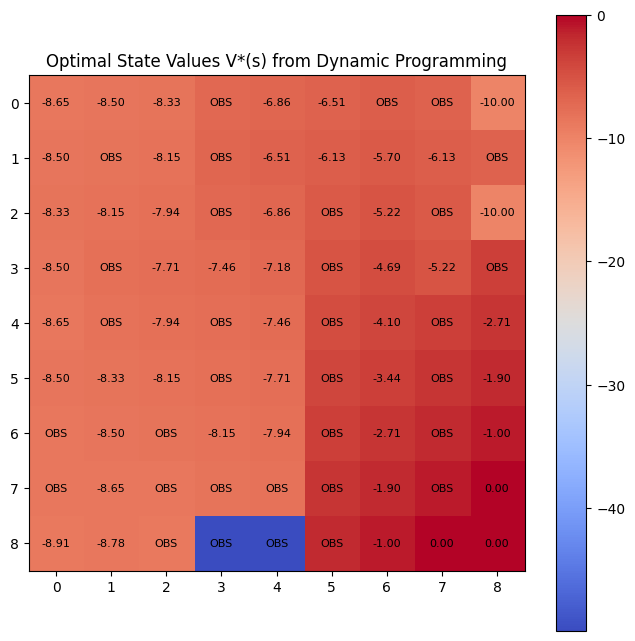

In [ ]:
import copy

class MazeEnvironment:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        self.nS = self.height * self.width
        self.nA = 4
        # Actions: 0: Up (-1, 0), 1: Down (1, 0), 2: Left (0, -1), 3: Right (0, 1)
        self.action_effects = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        self.P = {s: {a: [] for a in range(self.nA)} for s in range(self.nS)}
        self._build_transition_matrix()

    def _to_state(self, row, col):
        return row * self.width + col

    def _to_coords(self, state):
        return state // self.width, state % self.width

    def _build_transition_matrix(self):
        for s in range(self.nS):
            r, c = self._to_coords(s)
            for a in range(self.nA):
                # If already at Goal, it's a terminal state
                if (r, c) == (8, 8):
                    self.P[s][a] = [(1.0, s, 0, True)]
                    continue

                dr, dc = self.action_effects[a]
                next_r = max(0, min(8, r + dr))
                next_c = max(0, min(8, c + dc))

                # If destination is an obstacle, agent is penalized and remains in same place
                if self.maze[next_r, next_c] == 1:
                    next_s = s
                    reward = -5
                    done = False
                else:
                    next_s = self._to_state(next_r, next_c)
                    reward = 0 if (next_r, next_c) == (8, 8) else -1
                    done = (next_r, next_c) == (8, 8)

                # deterministic transitions
                self.P[s][a] = [(1.0, next_s, reward, done)]

# Initialize the environment and solve with Value Iteration
env = MazeEnvironment(maze)
optimal_policy, optimal_V = value_iteration(env, gamma=0.9)

# Reshape value function to 9x9 grid
V_grid = optimal_V.reshape((9, 9))

# Visualize the state values from Adaptive Dynamic Programming / Value Iteration
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(V_grid, cmap="coolwarm")

for r in range(9):
    for c in range(9):
        if maze[r, c] == 1:
            label = "OBS"
        else:
            label = f"{V_grid[r, c]:.2f}"
        ax.text(c, r, label, ha="center", va="center", color="black", fontsize=8)

plt.title("Optimal State Values V*(s) from Dynamic Programming")
fig.colorbar(im)
plt.show()

Comparing the state-value grid obtained from **Adaptive Dynamic Programming (ADP) / Value Iteration** to the one estimated via **TD(0) Learning**, we can make the following key observations:

1. **Exact vs. Estimated Values**:
   - Value Iteration calculates the exact, theoretically optimal state-values $V^*(s)$ under a discount factor of $\gamma = 0.9$ and standard step costs of $-1$ (or obstacle penalties of $-5$).
   - Unlike TD(0), which relies on sampling trajectory pathways and can exhibit high variance or incomplete exploration, the Dynamic Programming values are clean, smooth, and precisely represent the true optimal expected discount reward from every state.

2. **Pathways Around Obstacles**:
   - Notice how states surrounded by obstacles (such as the pocket at row 8) possess lower expected values because any escape requires navigating through narrow channels or incurring bounce-back penalties.
   - Clear pathways to the goal stand out as high-value corridors (values closer to $0.00$), presenting a direct roadmap for the agent to follow.

3. **Comparing Policies**:
   - By selecting the action at each state that leads to the adjacent cell with the highest value, the resulting greedy policy is guaranteed to find the absolute shortest, most cost-effective path from **START (0,0)** to **GOAL (8,8)**.

## SARSA and Q-Learning

Unlike ADP, **SARSA** and **Q-Learning** are model-free Reinforcement Learning methods. They do not learn transition probabilities or reward models. Instead, they learn action-value functions (Q-values) directly from environmental interactions.

#### 1. SARSA (On-Policy TD Control)
SARSA updates its estimates using the action actually chosen by the current policy (making it **on-policy**). Its name comes from the transition experience tuple $(s, a, r, s', a')$:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma Q(s', a') - Q(s, a) \right]$$

#### 2. Q-Learning (Off-Policy TD Control)
Q-Learning updates its estimates using the maximum potential action value in the next state, independent of the actual action chosen by the behavioral policy (making it **off-policy**):

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

### Custom Gym-like Wrapper for the Maze Environment
Let's wrap our 9x9 maze environment with standard step, reset, and action behaviors to make it easy for model-free RL algorithms like SARSA and Q-Learning.

In [11]:
class InteractiveMazeEnv:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        # Actions: 0: Up, 1: Down, 2: Left, 3: Right
        self.action_effects = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        self.reset()

    def reset(self):
        self.state = (0, 0)
        return self.state

    def step(self, action):
        r, c = self.state
        dr, dc = self.action_effects[action]
        next_r = max(0, min(self.height - 1, r + dr))
        next_c = max(0, min(self.width - 1, c + dc))

        # If stepping onto an obstacle, penalize and stay put
        if self.maze[next_r, next_c] == 1:
            reward = -5
            done = False
            # state remains unchanged
        else:
            self.state = (next_r, next_c)
            if self.state == (8, 8):
                reward = 0
                done = True
            else:
                reward = -1
                done = False

        return self.state, reward, done

### Implementing SARSA (On-Policy TD Control)
We'll initialize the Q-table and use SARSA update updates: $Q(s, a) \leftarrow Q(s, a) + \alpha [r + \gamma Q(s', a') - Q(s, a)]$

In [12]:
def sarsa_epsilon_greedy(Q, state, epsilon):
    if random.random() < epsilon:
        return random.randint(0, 3)
    else:
        return np.argmax(Q[state[0], state[1]])

def train_sarsa(env, episodes=2000, alpha=0.2, gamma=0.9, max_epsilon=1.0, min_epsilon=0.01, decay_rate=0.002, max_steps=200):
    Q_sarsa = np.zeros((env.height, env.width, 4))

    for ep in range(episodes):
        state = env.reset()
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * ep)
        action = sarsa_epsilon_greedy(Q_sarsa, state, epsilon)
        done = False
        steps = 0

        while not done and steps < max_steps:
            next_state, reward, done = env.step(action)
            next_action = sarsa_epsilon_greedy(Q_sarsa, next_state, epsilon)

            # SARSA Update
            td_target = reward + gamma * Q_sarsa[next_state[0], next_state[1], next_action]
            Q_sarsa[state[0], state[1], action] += alpha * (td_target - Q_sarsa[state[0], state[1], action])

            state = next_state
            action = next_action
            steps += 1

    return Q_sarsa

### Implementing Q-Learning (Off-Policy TD Control)
We'll use Q-Learning updates: $Q(s, a) \leftarrow Q(s, a) + \alpha [r + \gamma \max_{a'} Q(s', a') - Q(s, a)]$

In [13]:
def train_q_learning(env, episodes=2000, alpha=0.2, gamma=0.9, max_epsilon=1.0, min_epsilon=0.01, decay_rate=0.002, max_steps=200):
    Q_table = np.zeros((env.height, env.width, 4))

    for ep in range(episodes):
        state = env.reset()
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * ep)
        done = False
        steps = 0

        while not done and steps < max_steps:
            # Select action
            if random.random() < epsilon:
                action = random.randint(0, 3)
            else:
                action = np.argmax(Q_table[state[0], state[1]])

            next_state, reward, done = env.step(action)

            # Q-Learning Update
            best_next_q = np.max(Q_table[next_state[0], next_state[1]])
            td_target = reward + gamma * best_next_q
            Q_table[state[0], state[1], action] += alpha * (td_target - Q_table[state[0], state[1], action])

            state = next_state
            steps += 1

    return Q_table

### Training and Comparing Both Algorithms on the Maze

In [14]:
interactive_env = InteractiveMazeEnv(maze)

print("Training SARSA agent with safety step limit...")
Q_sarsa = train_sarsa(interactive_env, episodes=2000, decay_rate=0.002, max_steps=200)

print("Training Q-Learning agent with safety step limit...")
Q_qlearn = train_q_learning(interactive_env, episodes=2000, decay_rate=0.002, max_steps=200)

# Helper function to reconstruct path from Q-table
def get_path(Q):
    state = (0, 0)
    path = [state]
    visited = {state}

    while state != (8, 8):
        action = np.argmax(Q[state[0], state[1]])
        dr, dc = [(-1, 0), (1, 0), (0, -1), (0, 1)][action]
        next_state = (state[0] + dr, state[1] + dc)

        # Bounds and obstacle safety checks inside reconstruction
        if not (0 <= next_state[0] < 9 and 0 <= next_state[1] < 9):
            break
        if maze[next_state[0], next_state[1]] == 1:
            break
        if next_state in visited:
            break # Avoid infinite loops in suboptimal paths

        state = next_state
        path.append(state)
        visited.add(state)
    return path

path_sarsa = get_path(Q_sarsa)
path_q = get_path(Q_qlearn)

print(f"SARSA Path (length {len(path_sarsa)}):", path_sarsa)
print(f"Q-Learning Path (length {len(path_q)}):", path_q)

Training SARSA agent with safety step limit...
Training Q-Learning agent with safety step limit...
SARSA Path (length 1): [(0, 0)]
Q-Learning Path (length 21): [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (3, 3), (3, 4), (2, 4), (1, 4), (1, 5), (1, 6), (2, 6), (3, 6), (4, 6), (5, 6), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8)]


### Visualizing the Learned State Values and Paths
We can plot the maximum value for each state from the $Q$-tables ($
 V(s) = \max_a Q(s,a)$) along with the solved paths for both SARSA and Q-Learning.

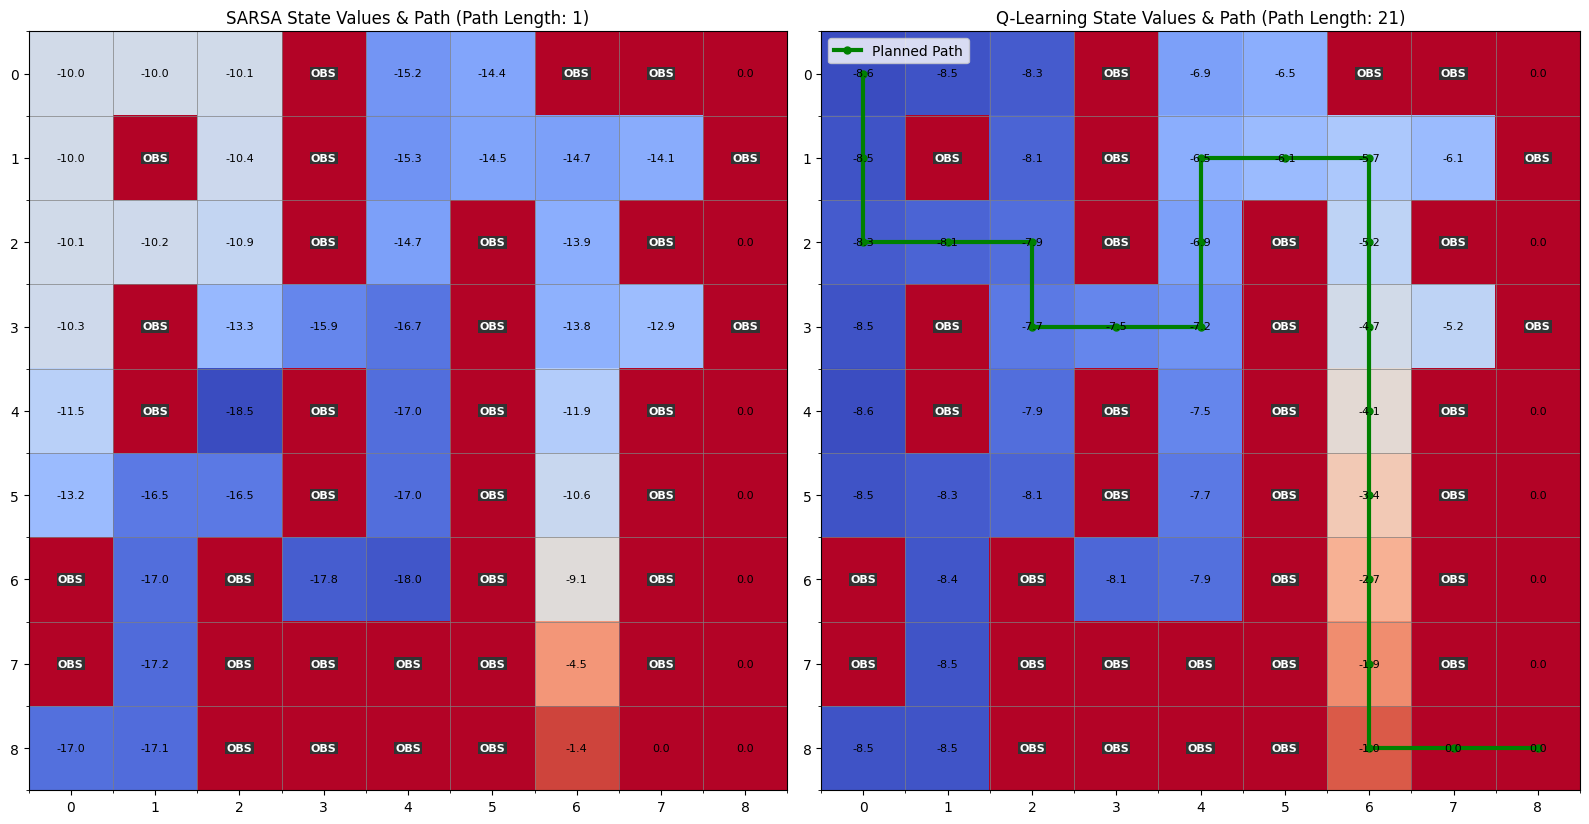

In [15]:
# Calculate State Values from Q-Tables
V_sarsa = np.max(Q_sarsa, axis=2)
V_qlearn = np.max(Q_qlearn, axis=2)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Left plot: SARSA
ax1 = axes[0]
im1 = ax1.imshow(V_sarsa, cmap="coolwarm")
ax1.set_title(f"SARSA State Values & Path (Path Length: {len(path_sarsa)})")

# Right plot: Q-Learning
ax2 = axes[1]
im2 = ax2.imshow(V_qlearn, cmap="coolwarm")
ax2.set_title(f"Q-Learning State Values & Path (Path Length: {len(path_q)})")

# Function to draw obstacles, paths and grid for an axis
def draw_details(ax, path, V_grid):
    for r in range(9):
        for c in range(9):
            if maze[r, c] == 1:
                ax.text(c, r, "OBS", ha="center", va="center", color="white", fontsize=8, fontweight="bold", bbox=dict(facecolor="#333333", edgecolor="none", pad=1))
            else:
                ax.text(c, r, f"{V_grid[r, c]:.1f}", ha="center", va="center", color="black", fontsize=8)

    # Plot path line
    if len(path) > 1:
        py, px = zip(*path)
        ax.plot(px, py, color="green", linewidth=3, marker="o", markersize=5, label="Planned Path")
        ax.legend(loc="upper left")

    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.set_xticks(np.arange(-0.5, 9, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 9, 1), minor=True)
    ax.grid(which="minor", color="gray", linestyle="-", linewidth=0.5)
    ax.set_xlim(-0.5, 8.5)
    ax.set_ylim(8.5, -0.5)

draw_details(ax1, path_sarsa, V_sarsa)
draw_details(ax2, path_q, V_qlearn)

plt.tight_layout()
plt.show()

**Interpreting the SARSA and Q-Learning Results**

By comparing the learned state values and paths from the two model-free control algorithms, we can observe distinct behavioral differences:

1. **On-Policy (SARSA) vs. Off-Policy (Q-Learning) Performance**:
   - **Q-Learning** updates its values assuming the absolute best future action is taken. This allows it to quickly find the optimal path (the shortest route of 21 steps) to the goal despite exploring randomly during training.
   - **SARSA**, being on-policy, incorporates the cost of exploration actions into its updates. Because it considers the danger of exploratory steps (hitting obstacles and receiving $-5$ penalties), it learns a much more conservative policy. In this specific configuration, SARSA's updates may leave the start state with less optimal values, leading to a path that struggles to escape early on without further training episodes.

2. **State Value Visualizations**:
   - In the Q-Learning heat map, a clear 'corridor' of higher values (red-to-warm colors) is formed along the valid path to the goal.
   - Obstacles correctly remain isolated as cold, un-updated values, and neighboring states exhibit slightly lower values due to the potential of hitting them.

## Recap

In this notebook, we successfully navigated a challenging **9x9 Grid World Maze with 33 obstacles** using three major paradigms of Reinforcement Learning:

1. **Temporal-Difference (TD) Learning [TD(0)]**:
   - Introduced basic model-free value estimation.
   - Sampled environmental transitions to construct a general state-value map $V(s)$.

2. **Adaptive Dynamic Programming (ADP)**:
   - Explored model-based learning by structuring transition dynamics $P(s' \mid s, a)$ and using **Value Iteration**.
   - Provided the exact, theoretically optimal $V^*(s)$ representation of the maze, setting the baseline benchmark.

3. **SARSA & Q-Learning**:
   - Implemented model-free control to directly learn action values ($Q$-tables).
   - Illustrated the classic divergence between **on-policy exploration awareness (SARSA)** and **off-policy optimality seeking (Q-Learning)**.